# LM3 Lab — Taylor Series and Approximation

Companion notebook to **From Calculus to Kelly, LM3**. It rebuilds every exhibit and computational example in the module from verified price files, and solves the computational practice problems.

| Part | Rebuilds |
|:--|:--|
| 1 | Taylor polynomials and Lagrange bounds (Exhibit 3, Examples 1 and 4) |
| 2 | Total-return series with dividends and splits, verified |
| 3 | Simple vs log returns (Section 5); the two worst days (Example 3) |
| 4 | Volatility drag across sampling frequencies (Exhibit 5, Examples 5 and 6) |
| 5 | 00631L decomposition: power, drag, residual (Exhibits 6–8) |
| 6 | TQQQ in 2022 (Example 7) |
| 7 | Duration and convexity (Example 8, Exhibit 9) |
| 8 | Practice-problem solutions and an extension exercise |

**Data.** `data/` holds a snapshot of FinMind `TaiwanStockPrice` closes for 0050 and 00631L (2014-10-31 → 2026-10-08), 0050 cash dividends from `TaiwanStockDividendResult`, and QQQ/TQQQ adjusted closes for 2022 from `USStockPrice`, retrieved 2026-10-10. Every daily close was checked against FinMind's own `spread` column (close − previous close); the only mismatches are ex-dividend and split days, which Part 2 handles explicitly.

**Environment.** `uv pip install polars pyarrow numpy matplotlib` (plus `requests` only if you use the optional live refresh).

In [1]:
from pathlib import Path
import math
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

DATA = Path("data")
pl.Config.set_tbl_rows(30)
pl.Config.set_float_precision(6)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

## Part 1 — Taylor polynomials and the Lagrange bound

For $\ln(1+x)$ the order-$n$ Maclaurin polynomial is $T_n(x)=\sum_{k=1}^n (-1)^{k+1}x^k/k$ (eq. 3.3), and the Lagrange remainder (eq. 3.5) gives
$|\ln(1+x)-T_n(x)| \le |x|^{n+1}/\big((n+1)\,b^{n+1}\big)$ with $b=1$ for $x\ge 0$ and $b=1+x$ for $x<0$.

In [2]:
def taylor_log1p(x, n):
    return sum((-1) ** (k + 1) * x**k / k for k in range(1, n + 1))

def bound_log1p(x, n):
    b = 1.0 if x >= 0 else 1.0 + x
    return abs(x) ** (n + 1) / ((n + 1) * b ** (n + 1))

def taylor_exp(x, n):
    return sum(x**k / math.factorial(k) for k in range(n + 1))

xs = [-0.20, -0.10, -0.05, -0.01, 0.01, 0.05, 0.10, 0.20, 0.50]
x = pl.col("x")
ex3 = pl.DataFrame({"x": xs}).with_columns(
    x.log1p().alias("ln(1+x)"),
    (x - x**2 / 2).alias("T2"),
    (x.abs() ** 3 / (3 * pl.when(x >= 0).then(1.0).otherwise(1 + x) ** 3)).alias("bound"),   # Lagrange bound, n = 2
).with_columns((pl.col("ln(1+x)") - pl.col("T2")).alias("error")).select("x", "ln(1+x)", "T2", "error", "bound")
assert (ex3["error"].abs() <= ex3["bound"]).all()
ex3   # Exhibit 3

x,ln(1+x),T2,error,bound
f64,f64,f64,f64,f64
-0.200000,-0.223144,-0.220000,-0.003144,0.005208
-0.100000,-0.105361,-0.105000,-0.000361,0.000457
-0.050000,-0.051293,-0.051250,-0.000043,0.000049
-0.010000,-0.010050,-0.010050,-0.000000,0.000000
0.010000,0.009950,0.009950,0.000000,0.000000
0.050000,0.048790,0.048750,0.000040,0.000042
0.100000,0.095310,0.095000,0.000310,0.000333
0.200000,0.182322,0.180000,0.002322,0.002667
0.500000,0.405465,0.375000,0.030465,0.041667


In [3]:
# Example 1: ln(1.05) and e^0.05 with orders 1-3
for n in (1, 2, 3):
    print(f"n={n}:  ln err {math.log1p(0.05) - taylor_log1p(0.05, n):+.7f}   exp err {math.exp(0.05) - taylor_exp(0.05, n):+.7f}")

# Example 4: doubling time and the rule of 72
for R in (0.02, 0.06, 0.08, 0.12):
    print(f"R={R:.0%}: exact {math.log(2)/math.log1p(R):6.3f}  0.693/R+0.347 {math.log(2)/R + math.log(2)/2:6.3f}  rule of 72 {72/(100*R):6.3f}")

n=1:  ln err -0.0012098   exp err +0.0012711
n=2:  ln err +0.0000402   exp err +0.0000211
n=3:  ln err -0.0000015   exp err +0.0000003
R=2%: exact 35.003  0.693/R+0.347 35.004  rule of 72 36.000
R=6%: exact 11.896  0.693/R+0.347 11.899  rule of 72 12.000
R=8%: exact  9.006  0.693/R+0.347  9.011  rule of 72  9.000
R=12%: exact  6.116  0.693/R+0.347  6.123  rule of 72  6.000


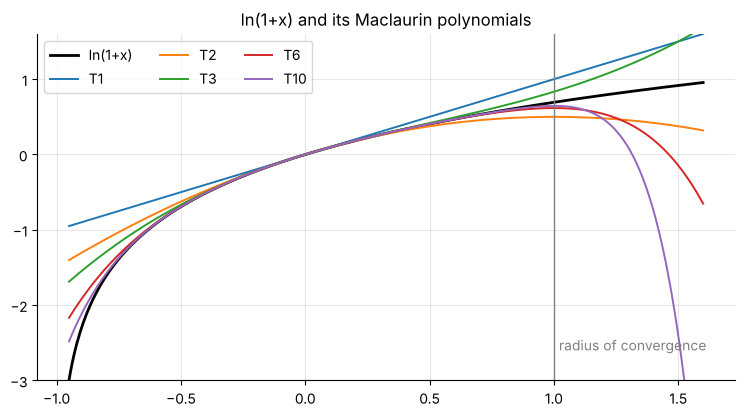

In [4]:
x = np.linspace(-0.95, 1.6, 400)
fig, ax = plt.subplots()
ax.plot(x, np.log1p(x), color="black", lw=2, label="ln(1+x)")
for n in (1, 2, 3, 6, 10):
    ax.plot(x, [taylor_log1p(v, n) for v in x], lw=1.4, label=f"T{n}")
ax.axvline(1, color="grey", lw=1); ax.text(1.02, -2.6, "radius of convergence", color="grey")
ax.set_ylim(-3, 1.6); ax.set_title("ln(1+x) and its Maclaurin polynomials"); ax.legend(ncol=3)
plt.show()

## Part 2 — Total-return series, corporate actions, verification

* **0050** pays cash dividends; on an ex-date $t$ the total return is $R_t=(P_t+D_t)/P_{t-1}-1$. It had a 4-for-1 split effective **2025-06-18**.
* **00631L** paid no dividends in the sample and split 22-for-1 effective **2026-03-31**.
* On a split day the return is $P_t/(P_{t-1}/k)-1$ for split ratio $k$.

The checksum below confirms that every close agrees with FinMind's `spread` except on those corporate-action days.

In [5]:
SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")

def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    chk = df.with_columns((pl.col("close") - pl.col("close").shift(1) - pl.col("spread")).abs().alias("gap")).filter(pl.col("gap") > 0.005)
    return df, chk

for sym in ("0050", "00631L"):
    df, chk = load_raw(sym)
    expected = set(div["date"]) | {SPLITS[sym][0]} if sym == "0050" else {SPLITS[sym][0]}
    unexplained = set(chk["date"]) - expected
    print(f"{sym}: {df.height} rows, checksum mismatches {chk.height}, unexplained {sorted(unexplained)}")
    assert not unexplained

0050: 2907 rows, checksum mismatches 23, unexplained []
00631L: 2908 rows, checksum mismatches 1, unexplained []


In [6]:
def total_returns(sym):
    df, _ = load_raw(sym)
    sd, k = SPLITS[sym]
    d = div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050" else pl.DataFrame({"date": [], "D": []}, schema={"date": pl.Utf8, "D": pl.Float64})
    return (df.join(d, on="date", how="left")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == sd).then(k).otherwise(1).cast(pl.Float64).alias("split"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("split").alias(f"S_{sym}")))

# align on common trading dates (each fund had a short split-related trading halt), then compute returns
both = total_returns("0050").join(total_returns("00631L"), on="date", how="inner").sort("date")
ret = (both.with_columns(
        ((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("S_0050")) - 1).alias("R_0050"),
        ((pl.col("P_00631L") + pl.col("D_00631L")) / (pl.col("P_00631L").shift(1) / pl.col("S_00631L")) - 1).alias("R_00631L"))
        .drop_nulls("R_0050")
        .with_columns(pl.col("date").str.to_date())
        .select("date", "R_0050", "R_00631L"))
print(ret.height, "daily returns from", ret["date"][0], "to", ret["date"][-1])
ret.sort("R_0050").head(5)   # worst days: 2025-04-07, 2024-08-05, ...

2902 daily returns from 2014-11-03 to 2026-10-08


date,R_0050,R_00631L
date,f64,f64
2025-04-07,-0.100000,-0.199950
2024-08-05,-0.091299,-0.192237
2018-10-11,-0.070270,-0.153743
2026-07-17,-0.058741,-0.134983
2020-03-19,-0.058379,-0.138943


## Part 3 — Simple vs log returns (Section 5)

Equation (3.6): $r=R-R^2/2+O(R^3)$, so the mean daily gap should be close to $\tfrac12\overline{R^2}=\tfrac12(s^2+\bar R^2)$.

In [7]:
R = ret["R_0050"].to_numpy(); RL = ret["R_00631L"].to_numpy()
r = np.log1p(R)
print(f"mean R            {R.mean():.6%}")
print(f"mean r            {r.mean():.6%}")
print(f"gap               {(R.mean() - r.mean())*1e4:.3f} bp/day")
print(f"half mean square  {(R**2).mean()/2*1e4:.3f} bp/day")
print(f"half variance     {R.var()/2*1e4:.3f} bp/day")
k = ((R - R.mean())**4).mean() / R.var()**2 - 3
print(f"excess kurtosis   {k:.2f}   (fat tails: see LM15)")

# Example 3: the two worst days, exact log return vs T1, T2 and the Lagrange bound
for d in ("2024-08-05", "2025-04-07"):
    x = ret.filter(pl.col("date") == pl.lit(d).str.to_date())["R_0050"][0]
    ex = math.log1p(x)
    print(f"{d}: R={x:.6f} ln={ex:.6f}  T1 err {(x-ex)*1e4:.1f} bp  T2 err {(taylor_log1p(x,2)-ex)*1e4:.1f} bp  bound {bound_log1p(x,2)*1e4:.1f} bp")

mean R            0.087120%
mean r            0.079422%
gap               0.770 bp/day
half mean square  0.771 bp/day
half variance     0.767 bp/day
excess kurtosis   8.12   (fat tails: see LM15)
2024-08-05: R=-0.091299 ln=-0.095740  T1 err 44.4 bp  T2 err 2.7 bp  bound 3.4 bp
2025-04-07: R=-0.100000 ln=-0.105361  T1 err 53.6 bp  T2 err 3.6 bp  bound 4.6 bp


## Part 4 — Volatility drag across sampling frequencies (Exhibit 5)

$R_G\approx\bar R-s^2/2$ (3.9) and $g\approx\bar R-(s^2+\bar R^2)/2$ (3.8), with $s^2$ the population variance.

In [8]:
wealth = ret.select("date", (1 + pl.col("R_0050")).cum_prod().alias("W"))

def period_returns(every):
    if every == "1d":
        w = wealth["W"].to_numpy()
    else:
        w = wealth.group_by_dynamic("date", every=every).agg(pl.col("W").last()).sort("date")["W"].to_numpy()
    w = np.concatenate([[1.0], w])
    Rk = w[1:] / w[:-1] - 1
    return Rk[1:-1] if every == "1y" else Rk   # annual: full calendar years 2015-2025 only

rows = []
for label, every in [("Daily", "1d"), ("Weekly", "1w"), ("Monthly", "1mo"), ("Quarterly", "1q"), ("Annual", "1y")]:
    Rk = period_returns(every); mu, s2 = Rk.mean(), Rk.var(); g = np.log1p(Rk).mean(); RG = np.expm1(g)
    rows.append({"period": label, "n": len(Rk), "mean": mu, "sd": math.sqrt(s2), "R_G": RG, "mu - s2/2": mu - s2/2,
                 "err_bp": (mu - s2/2 - RG)*1e4, "g": g, "mu - (s2+mu2)/2": mu - (s2 + mu*mu)/2, "err_g_bp": (mu - (s2+mu*mu)/2 - g)*1e4})
pl.DataFrame(rows)

period,n,mean,sd,R_G,mu - s2/2,err_bp,g,mu - (s2+mu2)/2,err_g_bp
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""Daily""",2902,0.000871,0.012385,0.000795,0.000795,-0.000275,0.000794,0.000794,-0.000915
"""Weekly""",615,0.004065,0.024953,0.003755,0.003754,-0.008103,0.003748,0.003746,-0.020420
"""Monthly""",144,0.017683,0.056489,0.016135,0.016087,-0.471688,0.016006,0.015931,-0.747327
"""Quarterly""",49,0.053673,0.109530,0.048161,0.047674,-4.870816,0.047037,0.046234,-8.036449
"""Annual""",11,0.186063,0.201728,0.167210,0.165716,-14.937640,0.154616,0.148407,-62.098216


In [9]:
# Example 5: calendar-year total returns 2020-2024
annual = (ret.group_by(pl.col("date").dt.year().alias("year"))
             .agg((1 + pl.col("R_0050")).product().sub(1).alias("R_0050"), (1 + pl.col("R_00631L")).product().sub(1).alias("R_00631L"))
             .sort("year"))
sub = annual.filter(pl.col("year").is_between(2020, 2024))["R_0050"].to_numpy()
mu, s2 = sub.mean(), sub.var(); RG = np.prod(1 + sub) ** (1 / len(sub)) - 1
print([f"{v:.2%}" for v in sub]); print(f"mean {mu:.3%}  R_G {RG:.3%}  approx {mu - s2/2:.3%}  s {math.sqrt(s2):.3%}")

# Example 6: the +2% / -1% bet
mu, s2 = 0.005, 0.000225
RG, g = math.sqrt(1.02 * 0.99) - 1, (math.log(1.02) + math.log(0.99)) / 2
print(f"Example 6: R_G {RG:.5%} vs {mu - s2/2:.5%} (err {(mu - s2/2 - RG)*1e4:.4f} bp);  g {g:.5%} vs {mu - (s2 + mu*mu)/2:.5%} (err {(mu - (s2+mu*mu)/2 - g)*1e4:.4f} bp)")
annual

['31.08%', '21.97%', '-21.34%', '27.40%', '48.67%']
mean 21.557%  R_G 18.957%  approx 18.856%  s 23.240%
Example 6: R_G 0.48881% vs 0.48875% (err -0.0055 bp);  g 0.48761% vs 0.48750% (err -0.0115 bp)


year,R_0050,R_00631L
i32,f64,f64
2014,0.023737,0.065842
2015,-0.063093,-0.165351
2016,0.196442,0.391764
2017,0.181338,0.398241
2018,-0.049511,-0.103803
2019,0.335157,0.708679
2020,0.310844,0.680672
2021,0.219709,0.622222
2022,-0.213416,-0.364384


## Part 5 — Leveraged ETF decomposition (Exhibits 6–8)

From (3.10)–(3.11): $\ln\frac{V_T}{V_0} = L\ln G + \sum_t\big[\ln(1+LR_t)-L\ln(1+R_t)\big] + \text{residual}$, and the middle term is $\approx-\tfrac{L(L-1)}{2}\sum_t R_t^2$.

In [10]:
def leverage_decomposition(R, RF, L):
    power = L * np.log1p(R).sum()
    exact = (np.log1p(L * R) - L * np.log1p(R)).sum()
    t2 = -L * (L - 1) / 2 * (R**2).sum()
    t3 = t2 + (L**3 - L) / 3 * (R**3).sum()
    t4 = t3 - (L**4 - L) / 4 * (R**4).sum()
    actual = np.log1p(RF).sum()
    return {"power": power, "exact_drag": exact, "taylor2": t2, "taylor3": t3, "taylor4": t4,
            "residual": actual - power - exact, "actual": actual}

full = leverage_decomposition(R, RL, 2)
years = (ret["date"][-1] - ret["date"][0]).days / 365.25 + 3/365.25   # base date is 2014-10-31
print({k: round(v, 4) for k, v in full.items()})
print(f"growth: 0050 x{np.prod(1+R):.2f}  exact daily 2x x{np.prod(1+2*R):.2f}  00631L x{np.prod(1+RL):.2f}")
print(f"drag per year {full['exact_drag']/years:.4f}  realized annual variance {R.var()*len(R)/years:.4f}  residual per year {full['residual']/years:.4f}")

{'power': np.float64(4.6097), 'exact_drag': np.float64(-0.4473), 'taylor2': np.float64(-0.4473), 'taylor3': np.float64(-0.4446), 'taylor4': np.float64(-0.4473), 'residual': np.float64(-0.3659), 'actual': np.float64(3.7965)}
growth: 0050 x10.02  exact daily 2x x64.22  00631L x44.54
drag per year -0.0375  realized annual variance 0.0373  residual per year -0.0307


In [11]:
yearly = []
for y in range(2015, 2026):
    m = (ret["date"].dt.year() == y).to_numpy()
    d = leverage_decomposition(R[m], RL[m], 2)
    yearly.append({"year": y, "0050": np.prod(1 + R[m]) - 1, "00631L": np.prod(1 + RL[m]) - 1, "2x0050": 2 * (np.prod(1 + R[m]) - 1),
                   "taylor2": d["taylor2"], "exact_drag": d["exact_drag"], "residual": d["residual"],
                   "exact_daily_2x": math.exp(d["power"] + d["exact_drag"]) - 1})
pl.DataFrame(yearly)   # Exhibit 8 (+ exact daily 2x column)

year,0050,00631L,2x0050,taylor2,exact_drag,residual,exact_daily_2x
i64,f64,f64,f64,f64,f64,f64,f64
2015,-0.063093,-0.165351,-0.126185,-0.026609,-0.026486,-0.023916,-0.145149
2016,0.196442,0.391764,0.392884,-0.022427,-0.022378,-0.005754,0.399796
2017,0.181338,0.398241,0.362675,-0.008754,-0.008721,0.010641,0.383440
2018,-0.049511,-0.103803,-0.099021,-0.027031,-0.028005,0.019966,-0.121519
2019,0.335157,0.708679,0.670313,-0.015164,-0.015034,-0.027343,0.756043
2020,0.310844,0.680672,0.621688,-0.052755,-0.052737,0.030588,0.630042
2021,0.219709,0.622222,0.439418,-0.031110,-0.030806,0.117378,0.442559
2022,-0.213416,-0.364384,-0.426832,-0.047619,-0.047719,0.074671,-0.410117
2023,0.273978,0.629310,0.547956,-0.019380,-0.019090,0.022958,0.592330


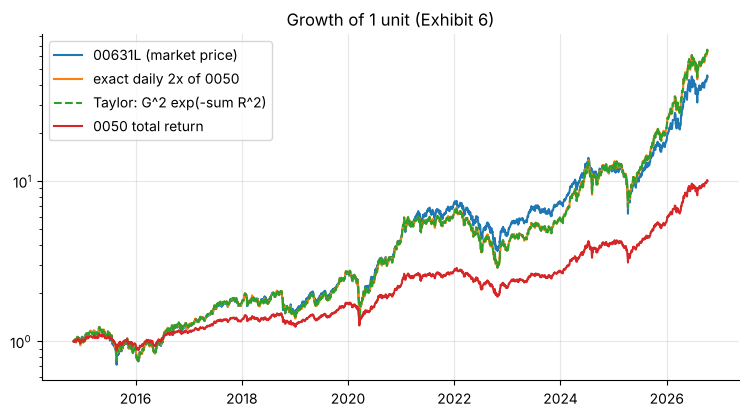

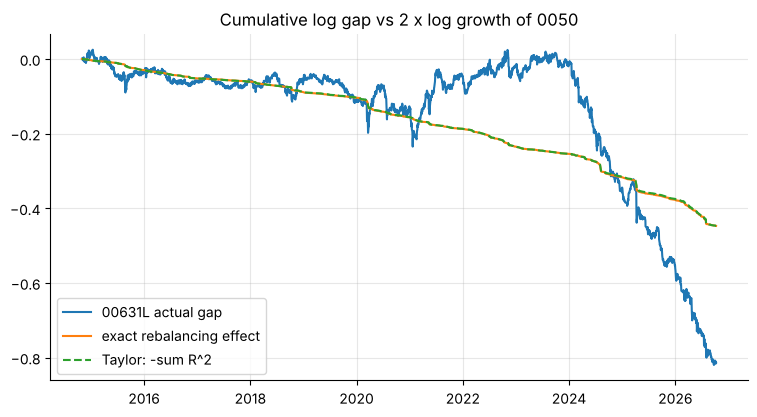

In [12]:
dates = np.concatenate([[np.datetime64("2014-10-31")], ret["date"].to_numpy()])
W0 = np.concatenate([[1], np.cumprod(1 + R)]); W2 = np.concatenate([[1], np.cumprod(1 + 2*R)])
WT = np.concatenate([[1], np.cumprod(1 + R)**2 * np.exp(-np.cumsum(R**2))]); WL = np.concatenate([[1], np.cumprod(1 + RL)])
fig, ax = plt.subplots()
ax.plot(dates, WL, label="00631L (market price)"); ax.plot(dates, W2, label="exact daily 2x of 0050")
ax.plot(dates, WT, "--", label="Taylor: G^2 exp(-sum R^2)"); ax.plot(dates, W0, label="0050 total return")
ax.set_yscale("log"); ax.set_title("Growth of 1 unit (Exhibit 6)"); ax.legend(); plt.show()

fig, ax = plt.subplots()
ax.plot(dates, np.concatenate([[0], np.cumsum(np.log1p(RL) - 2*np.log1p(R))]), label="00631L actual gap")
ax.plot(dates, np.concatenate([[0], np.cumsum(np.log1p(2*R) - 2*np.log1p(R))]), label="exact rebalancing effect")
ax.plot(dates, np.concatenate([[0], -np.cumsum(R**2)]), "--", label="Taylor: -sum R^2")
ax.set_title("Cumulative log gap vs 2 x log growth of 0050"); ax.legend(); plt.show()

## Part 6 — TQQQ in 2022 (Example 7)

Calendar-2022 returns use the adjusted close from 2021-12-31 to 2022-12-30; $L=3$, so the second-order drag coefficient is $L(L-1)/2=3$ and the third-order coefficient $(L^3-L)/3=8$.

In [13]:
qt = pl.read_csv(DATA / "QQQ_TQQQ_2022.csv").filter(pl.col("date").is_between(pl.lit("2021-12-31"), pl.lit("2022-12-30"))).sort("date")
q = qt["qqq_adj"].to_numpy(); t = qt["tqqq_adj"].to_numpy()
rq, rt = q[1:] / q[:-1] - 1, t[1:] / t[:-1] - 1
d3 = leverage_decomposition(rq, rt, 3)
print(f"QQQ {q[-1]/q[0]-1:.2%}  TQQQ {t[-1]/t[0]-1:.2%}  3 x QQQ {3*(q[-1]/q[0]-1):.2%}  RV {np.sum(rq**2):.4f}  ann. vol {rq.std()*math.sqrt(252):.1%}")
print({k: round(v, 4) for k, v in d3.items()})

QQQ -32.58%  TQQQ -79.09%  3 x QQQ -97.73%  RV 0.1030  ann. vol 32.1%
{'power': np.float64(-1.1825), 'exact_drag': np.float64(-0.3132), 'taylor2': np.float64(-0.309), 'taylor3': np.float64(-0.3107), 'taylor4': np.float64(-0.3132), 'residual': np.float64(-0.0692), 'actual': np.float64(-1.5649)}


## Part 7 — Duration and convexity (Example 8)

A 10-year bond with a 2% annual coupon, priced at a 2% yield. Derivatives are taken numerically with central differences.

In [14]:
def price(y, c=0.02, n=10, F=100.0):
    return sum(c * F / (1 + y) ** t for t in range(1, n + 1)) + F / (1 + y) ** n

y0, h = 0.02, 1e-5
P0 = price(y0)
Dmod = -(price(y0 + h) - price(y0 - h)) / (2 * h) / P0
C = (price(y0 + h) - 2 * P0 + price(y0 - h)) / h**2 / P0
print(f"P0={P0:.4f}  Dmod={Dmod:.4f}  C={C:.4f}")
pl.DataFrame([{"dy_bp": dy * 1e4, "exact": price(y0 + dy) / P0 - 1, "duration": -Dmod * dy,
               "duration+convexity": -Dmod * dy + 0.5 * C * dy * dy} for dy in (0.01, -0.01, 0.03)])

P0=100.0000  Dmod=8.9826  C=93.9955


dy_bp,exact,duration,duration+convexity
f64,f64,f64,f64
100.000000,-0.085302,-0.089826,-0.085126
-100.000000,0.094713,0.089826,0.094526
300.000000,-0.231652,-0.269478,-0.227180


## Part 8 — Practice-problem solutions (computational) and an extension

In [15]:
print("PP3 ", f"ln(0.92)={math.log1p(-0.08):.7f}  T2={taylor_log1p(-0.08, 2):.7f}  bound={bound_log1p(-0.08, 2):.7f}")
a = np.array([0.30, -0.20, 0.10]); print("PP4 ", f"geo={np.prod(1+a)**(1/3)-1:.4%}  approx={a.mean()-a.var()/2:.4%}")
print("PP6 ", f"geo={math.sqrt(1.6*0.6)-1:.3%}  approx={0.10-0.5**2/2:.3%}")
print("PP7 ", f"index={1.1*0.9-1:.2%}  fund={1.2*0.8-1:.2%}  taylor={(1.1*0.9)**2*math.exp(-0.02)-1:.2%}")
print("PP8 ", f"{1.2**3*math.exp(-3*0.09)-1:.2%}")
print("PP10", f"{-7.5*0.015+0.5*70*0.015**2:.3%}")
print("PP12", f"exact={math.log(2)/math.log1p(0.06):.3f}  approx={math.log(2)/0.06+math.log(2)/2:.3f}")
print("PP13", f"exact={1.03/1.025-1:.4%}  first={0.005:.4%}  second={0.005-0.025*0.005:.4%}")
m = ret["date"].dt.year().is_between(2020, 2023).to_numpy()
print("PP14", {k: round(v, 4) for k, v in leverage_decomposition(R[m], RL[m], 2).items()})

PP3  ln(0.92)=-0.0833816  T2=-0.0832000  bound=0.0002192
PP4  geo=4.5864%  approx=4.5556%
PP6  geo=-2.020%  approx=-2.500%
PP7  index=-1.00%  fund=-4.00%  taylor=-3.93%
PP8  31.91%
PP10 -10.463%
PP12 exact=11.896  approx=11.899
PP13 exact=0.4878%  first=0.5000%  second=0.4875%
PP14 {'power': np.float64(0.9427), 'exact_drag': np.float64(-0.1504), 'taylor2': np.float64(-0.1509), 'taylor3': np.float64(-0.1498), 'taylor4': np.float64(-0.1504), 'residual': np.float64(0.2456), 'actual': np.float64(1.038)}


### Extension: the inverse fund

For an inverse fund $L=-1$, the drag coefficient $L(L-1)/2$ equals $1$: a daily −1× fund suffers the **same** variance drag as a daily 2× fund. Fetch Yuanta Taiwan 50 Bear −1X (00632R) and test (3.11) with $L=-1$. The helper below refreshes data from the FinMind API with your own token (`FINMIND_TOKEN` environment variable); queries are limited in size, so it fetches year by year.

In [16]:
import os

def finmind(dataset, data_id, start, end):
    import requests
    out = []
    for y in range(int(start[:4]), int(end[:4]) + 1):
        s, e = max(start, f"{y}-01-01"), min(end, f"{y}-12-31")
        p = {"dataset": dataset, "data_id": data_id, "start_date": s, "end_date": e, "token": os.environ.get("FINMIND_TOKEN", "")}
        js = requests.get("https://api.finmindtrade.com/api/v4/data", params=p, timeout=30).json()
        out.extend(js.get("data", []))
    return pl.DataFrame(out)

# inv = finmind("TaiwanStockPrice", "00632R", "2015-01-01", "2026-10-08")   # uncomment to run